<a href="https://colab.research.google.com/github/nkoushik30/DL_Team_Collaborative_Project/blob/main/Text_Language_Identification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

import random
import os

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow Version:", tf.__version__)
print("Libraries imported successfully!")

TensorFlow Version: 2.21.0
Libraries imported successfully!


In [ ]:
df = pd.read_csv("dataset.csv")

print("Dataset Shape:", df.shape)
print("\nColumn Names:")
print(df.columns.tolist())

print("\nFirst 5 Records:")
display(df.head())

print("\nDataset Information:")
df.info()

Dataset Shape: (22000, 2)

Column Names:
['Text', 'language']

First 5 Records:


,Text,language
0,klement gottwaldi surnukeha palsameeriti ning ...,Estonian
1,sebes joseph pereira thomas på eng the jesuit...,Swedish
2,ถนนเจริญกรุง อักษรโรมัน thanon charoen krung เ...,Thai
3,விசாகப்பட்டினம் தமிழ்ச்சங்கத்தை இந்துப் பத்திர...,Tamil
4,de spons behoort tot het geslacht haliclona en...,Dutch



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 22000 entries, 0 to 21999
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   Text      22000 non-null  object
 1   language  22000 non-null  object
dtypes: object(2)
memory usage: 343.9+ KB


In [ ]:
df = df.dropna(subset=["Text", "language"])

df["Text"] = df["Text"].astype(str).str.strip()
df["language"] = df["language"].astype(str).str.strip()

df = df[df["Text"] != ""]

df = df.drop_duplicates(subset=["Text", "language"])

df = df.reset_index(drop=True)

print("Cleaned Dataset Shape:", df.shape)
print("Unique Languages:", df["language"].nunique())

print("\nLanguage Counts:")
print(df["language"].value_counts())

Cleaned Dataset Shape: (21858, 2)
Unique Languages: 22

Language Counts:
language
Japanese      1000
Thai          1000
Korean        1000
Chinese       1000
Urdu          1000
Turkish       1000
Romanian      1000
English       1000
Persian       1000
Estonian       999
Russian        999
Arabic         998
Portugese      997
Spanish        996
Dutch          995
Pushto         993
Swedish        992
French         990
Hindi          990
Tamil          981
Indonesian     975
Latin          953
Name: count, dtype: int64


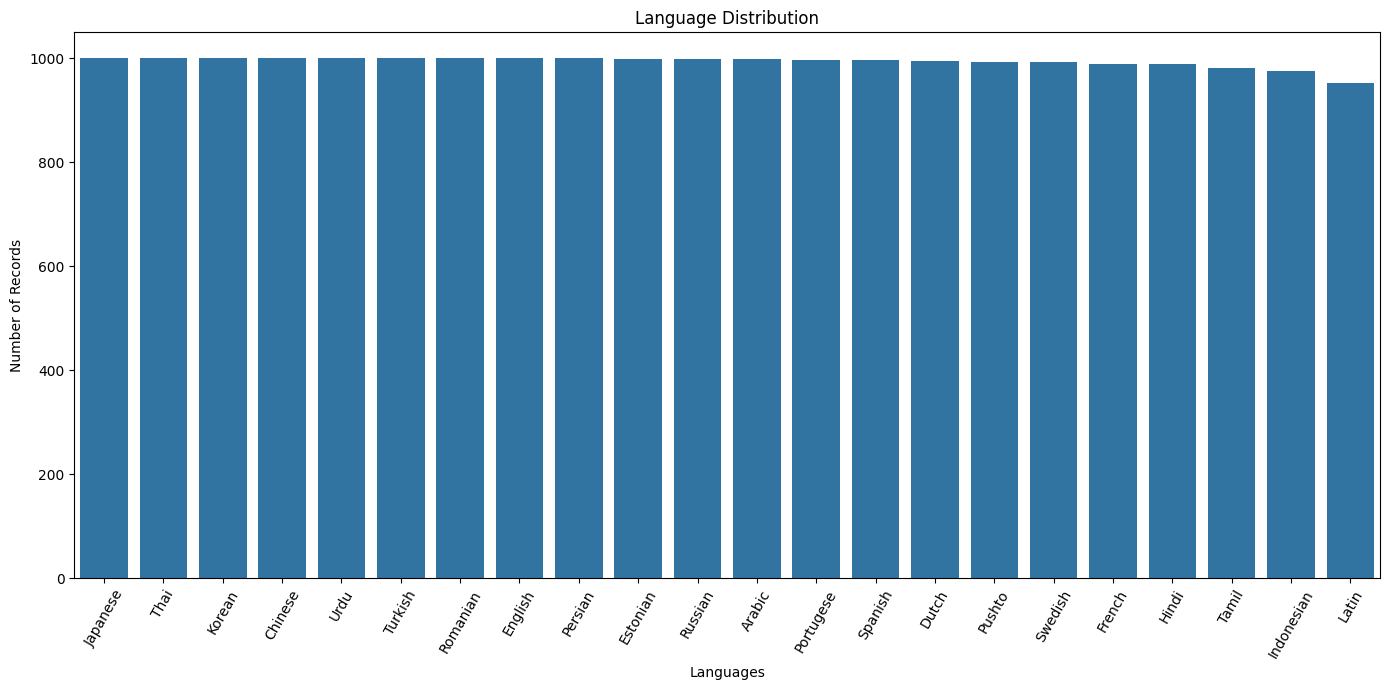

In [ ]:
plt.figure(figsize=(14, 7))

sns.countplot(
    data=df,
    x="language",
    order=df["language"].value_counts().index
)

plt.title("Language Distribution")
plt.xlabel("Languages")
plt.ylabel("Number of Records")
plt.xticks(rotation=60)
plt.tight_layout()

plt.savefig("class_distribution.png")
plt.show()

In [ ]:
X = df["Text"].values
y = df["language"].values

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=SEED,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=SEED,
    stratify=y_temp
)

print("Training Samples:", len(X_train))
print("Validation Samples:", len(X_val))
print("Testing Samples:", len(X_test))

Training Samples: 15300
Validation Samples: 3279
Testing Samples: 3279


In [ ]:
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()

y_train_encoded = label_encoder.fit_transform(y_train)

y_val_encoded = label_encoder.transform(y_val)

y_test_encoded = label_encoder.transform(y_test)

num_classes = len(label_encoder.classes_)

print("Number of Languages:", num_classes)

print("\nLanguage Encoding:")

for i, language in enumerate(label_encoder.classes_):
    print(language, ":", i)

Number of Languages: 22

Language Encoding:
Arabic : 0
Chinese : 1
Dutch : 2
English : 3
Estonian : 4
French : 5
Hindi : 6
Indonesian : 7
Japanese : 8
Korean : 9
Latin : 10
Persian : 11
Portugese : 12
Pushto : 13
Romanian : 14
Russian : 15
Spanish : 16
Swedish : 17
Tamil : 18
Thai : 19
Turkish : 20
Urdu : 21


In [ ]:
from tensorflow.keras.preprocessing.text import Tokenizer

tokenizer = Tokenizer(
    char_level=True,
    oov_token="<OOV>",
    lower=False,
    filters=""
)

tokenizer.fit_on_texts(X_train)

vocab_size = len(tokenizer.word_index) + 1

print("Vocabulary Size:", vocab_size)

print("\nSample Character Mapping:")

for char, index in list(tokenizer.word_index.items())[:30]:
    print(repr(char), ":", index)

Vocabulary Size: 6605

Sample Character Mapping:
'<OOV>' : 1
' ' : 2
'e' : 3
'a' : 4
'i' : 5
'n' : 6
'r' : 7
't' : 8
's' : 9
'o' : 10
'l' : 11
'ا' : 12
'd' : 13
'u' : 14
'm' : 15
'c' : 16
'و' : 17
'ر' : 18
'p' : 19
'ل' : 20
'ن' : 21
'g' : 22
'ی' : 23
'م' : 24
'د' : 25
'h' : 26
'k' : 27
'ه' : 28
'்' : 29
'b' : 30


In [ ]:
import os

os.makedirs("results", exist_ok=True)
os.makedirs("models", exist_ok=True)

print("Folders created successfully!")

Folders created successfully!


Minimum Length: 8
Maximum Length: 1341
Average Length: 358.4034640522876
95th Percentile: 884.0


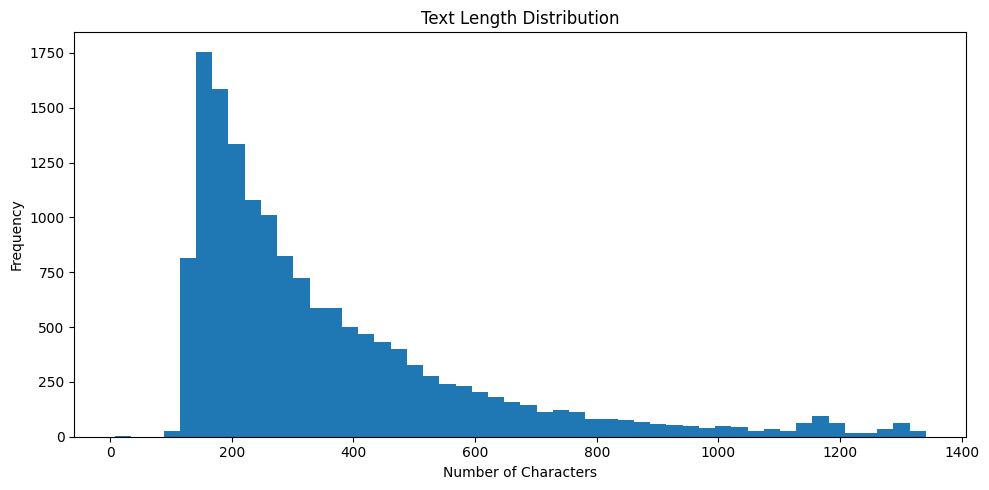

In [ ]:
text_lengths = [len(text) for text in X_train]

print("Minimum Length:", min(text_lengths))
print("Maximum Length:", max(text_lengths))
print("Average Length:", np.mean(text_lengths))
print("95th Percentile:", np.percentile(text_lengths, 95))

plt.figure(figsize=(10, 5))

plt.hist(text_lengths, bins=50)

plt.title("Text Length Distribution")
plt.xlabel("Number of Characters")
plt.ylabel("Frequency")

plt.tight_layout()
plt.savefig("results/text_length_distribution.png")
plt.show()

In [ ]:
X_train_seq = tokenizer.texts_to_sequences(X_train)

X_val_seq = tokenizer.texts_to_sequences(X_val)

X_test_seq = tokenizer.texts_to_sequences(X_test)

print("Sample Original Text:")
print(X_train[0])

print("\nNumerical Sequence:")
print(X_train_seq[0][:50])

Sample Original Text:
伊賀の自然を感受しながら、花を活け、料理をし、骨董を愛でる暮らしぶりは、随筆家の白洲正子にして「新しい茶人」と称せられ、白洲の著書『日本のたくみ』（年、新潮文庫）の「土楽さんの焼きもの 福森雅武」で、志村ふくみ、川瀬俊郎らと並び紹介された。また、中島誠之助監修の『新しい和食器の本』（年、主婦と生活社）の「全国陶郷の今を代表する人気陶芸家人『新作の器』」で、藤岡周平とともに伊賀焼きを代表する陶工として紹介された。白洲のほか、漆芸家で人間国宝の黒田辰秋、武者小路千家の千宗守など様々な人物と出会い、薫陶を受けた。人々は親しみを込めて「土楽さん」と呼ぶ。

Numerical Sequence:
[1103, 2610, 132, 446, 763, 206, 1178, 662, 209, 254, 219, 327, 128, 1458, 206, 764, 530, 128, 1260, 449, 206, 209, 128, 2917, 3581, 206, 1119, 208, 185, 3146, 327, 209, 1843, 331, 194, 128, 2150, 2790, 427, 132, 1299, 1318, 651, 465, 164, 209, 211, 329, 512, 209]


In [ ]:
from tensorflow.keras.preprocessing.sequence import pad_sequences

MAX_LEN = 600

X_train_pad = pad_sequences(
    X_train_seq,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

X_val_pad = pad_sequences(
    X_val_seq,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

X_test_pad = pad_sequences(
    X_test_seq,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

print("Training Shape:", X_train_pad.shape)
print("Validation Shape:", X_val_pad.shape)
print("Testing Shape:", X_test_pad.shape)

Training Shape: (15300, 600)
Validation Shape: (3279, 600)
Testing Shape: (3279, 600)


In [ ]:
for name, data in [
    ("Training", X_train_seq),
    ("Validation", X_val_seq),
    ("Testing", X_test_seq)
]:
    truncated = sum(len(seq) > MAX_LEN for seq in data)

    print(
        name,
        "Truncated:",
        truncated,
        "Percentage:",
        round(truncated / len(data) * 100, 2),
        "%"
    )

Training Truncated: 2063 Percentage: 13.48 %
Validation Truncated: 398 Percentage: 12.14 %
Testing Truncated: 426 Percentage: 12.99 %


In [ ]:
import json
import joblib

os.makedirs("models", exist_ok=True)

tokenizer_json = tokenizer.to_json()

with open("models/tokenizer.json", "w", encoding="utf-8") as file:
    file.write(tokenizer_json)

joblib.dump(
    label_encoder,
    "models/label_encoder.pkl"
)

print("Tokenizer saved successfully!")
print("Label Encoder saved successfully!")

Tokenizer saved successfully!
Label Encoder saved successfully!


In [ ]:
print("Vocabulary Size:", vocab_size)
print("Number of Classes:", num_classes)

print("\nTraining Data:", X_train_pad.shape)
print("Validation Data:", X_val_pad.shape)
print("Testing Data:", X_test_pad.shape)

print("\nTraining Labels:", y_train_encoded.shape)
print("Validation Labels:", y_val_encoded.shape)
print("Testing Labels:", y_test_encoded.shape)

print("\nPreprocessing Completed Successfully!")

Vocabulary Size: 6605
Number of Classes: 22

Training Data: (15300, 600)
Validation Data: (3279, 600)
Testing Data: (3279, 600)

Training Labels: (15300,)
Validation Labels: (3279,)
Testing Labels: (3279,)

Preprocessing Completed Successfully!


In [ ]:
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input,
    Embedding,
    LSTM,
    Dropout,
    Dense
)

from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint,
    ReduceLROnPlateau
)

print("TensorFlow:", tf.__version__)

print("Available GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
Available GPU: []


In [ ]:
MAX_LEN = 600

EMBEDDING_DIM = 128

LSTM_UNITS = 128

DENSE_UNITS = 64

DROPOUT_RATE = 0.3

BATCH_SIZE = 64

EPOCHS = 9

print("Vocabulary Size:", vocab_size)
print("Number of Classes:", num_classes)
print("Maximum Sequence Length:", MAX_LEN)

Vocabulary Size: 6605
Number of Classes: 22
Maximum Sequence Length: 600


In [ ]:
model = Sequential([

    Input(shape=(MAX_LEN,)),

    Embedding(
        input_dim=vocab_size,
        output_dim=EMBEDDING_DIM,
        mask_zero=True
    ),

    LSTM(
        LSTM_UNITS
    ),

    Dropout(DROPOUT_RATE),

    Dense(
        DENSE_UNITS,
        activation="relu"
    ),

    Dense(
        num_classes,
        activation="softmax"
    )
])

print("LSTM Model Created Successfully!")

LSTM Model Created Successfully!


In [ ]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model Compiled Successfully!")

Model Compiled Successfully!


In [ ]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 600, 128)       │       845,440 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 128)            │       131,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 22)             │         1,430 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 986,710 (3.76 MB)

 Trainable params: 986,710 (3.76 MB)

 Non-trainable params: 0 (0.00 B)

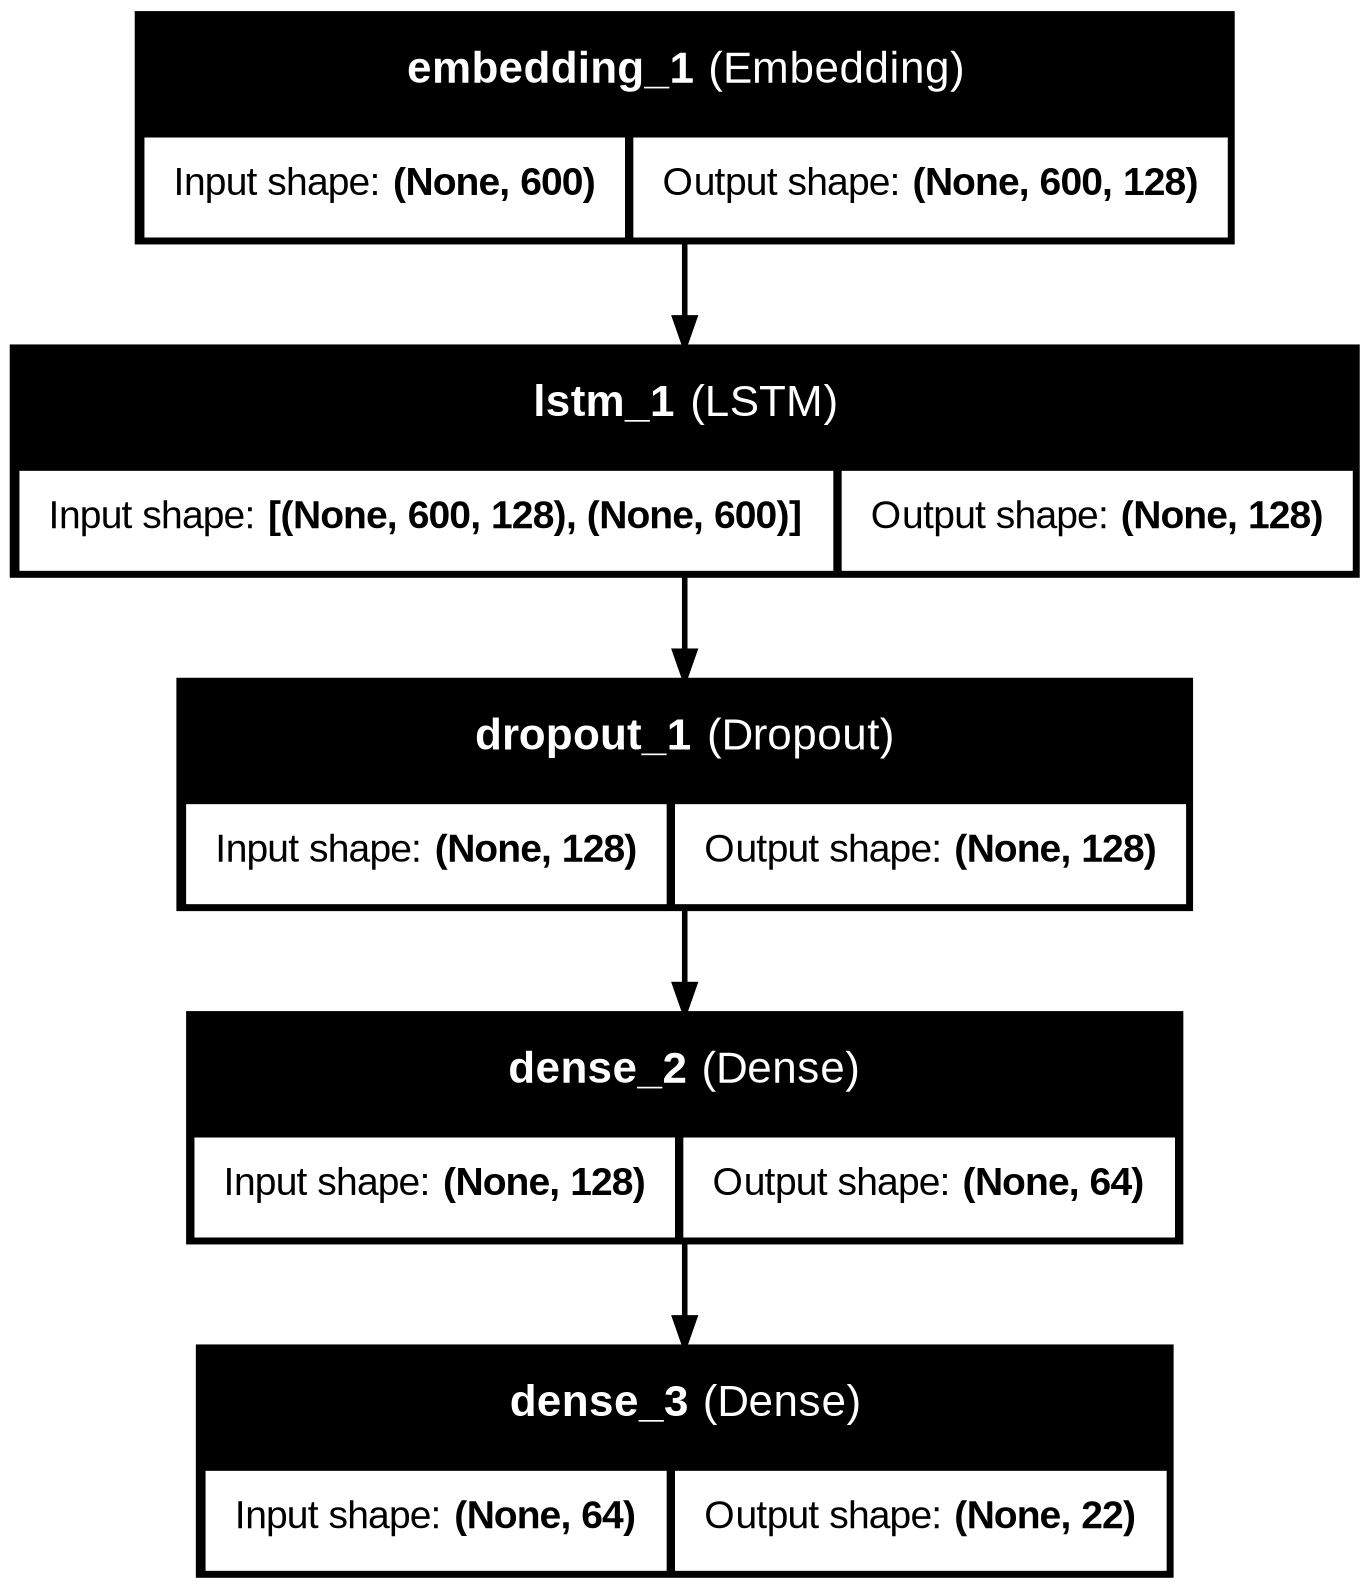

In [ ]:
tf.keras.utils.plot_model(
    model,
    to_file="results/model_architecture.png",
    show_shapes=True,
    show_layer_names=True
)

In [ ]:
os.makedirs("models", exist_ok=True)

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True,
    verbose=1
)

model_checkpoint = ModelCheckpoint(
    filepath="models/best_language_lstm.keras",
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=0.00001,
    verbose=1
)

callbacks = [
    early_stopping,
    model_checkpoint,
    reduce_lr
]

print("Callbacks configured successfully!")

Callbacks configured successfully!


In [ ]:
history = model.fit(
    X_train_pad,
    y_train_encoded,

    validation_data=(
        X_val_pad,
        y_val_encoded
    ),

    epochs=EPOCHS,

    batch_size=BATCH_SIZE,

    callbacks=callbacks,

    verbose=1
)

print("Model Training Completed!")

Epoch 1/9
240/240 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.3162 - loss: 2.2824
Epoch 1: val_loss improved from None to 1.24330, saving model to models/best_language_lstm.keras

Epoch 1: finished saving model to models/best_language_lstm.keras
240/240 ━━━━━━━━━━━━━━━━━━━━ 261s 1s/step - accuracy: 0.4510 - loss: 1.6999 - val_accuracy: 0.5987 - val_loss: 1.2433 - learning_rate: 0.0010
Epoch 2/9
240/240 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.6046 - loss: 1.1764
Epoch 2: val_loss improved from 1.24330 to 0.93022, saving model to models/best_language_lstm.keras

Epoch 2: finished saving model to models/best_language_lstm.keras
240/240 ━━━━━━━━━━━━━━━━━━━━ 256s 1s/step - accuracy: 0.6458 - loss: 1.0445 - val_accuracy: 0.6737 - val_loss: 0.9302 - learning_rate: 0.0010
Epoch 3/9
240/240 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.6569 - loss: 1.0545
Epoch 3: val_loss improved from 0.93022 to 0.71924, saving model to models/best_language_lstm.keras

Epoch 3: finished saving model t

In [ ]:
model.save("models/language_lstm.keras")

print("Trained model saved successfully!")

Trained model saved successfully!


In [ ]:
import json

history_df = pd.DataFrame(history.history)

history_df.to_csv(
    "results/training_history.csv",
    index=False
)

with open(
    "results/training_history.json",
    "w"
) as file:
    json.dump(history.history, file, indent=4)

best_epoch = np.argmin(history.history["val_loss"]) + 1

print("Completed Epochs:", len(history.history["loss"]))

print("Best Epoch:", best_epoch)

print("Best Validation Accuracy:",
      max(history.history["val_accuracy"]))

print("Best Validation Loss:",
      min(history.history["val_loss"]))

Completed Epochs: 9
Best Epoch: 9
Best Validation Accuracy: 0.9539493918418884
Best Validation Loss: 0.1843758374452591


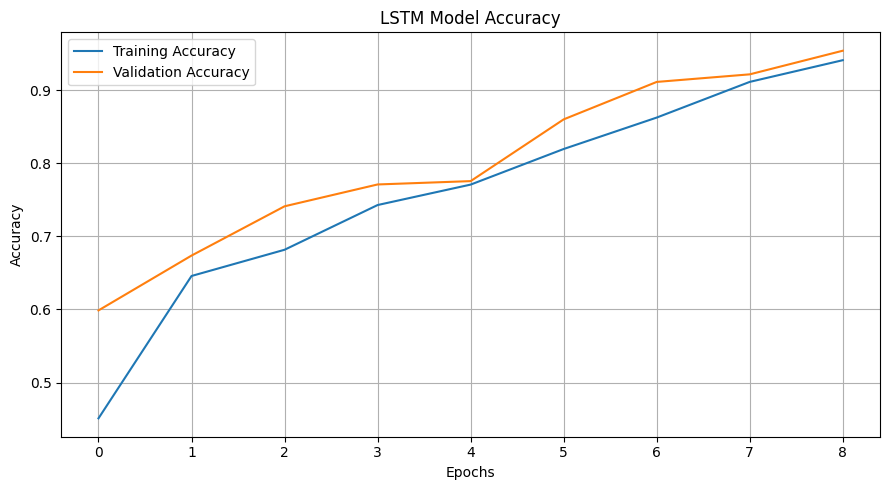

In [ ]:
plt.figure(figsize=(9, 5))

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("LSTM Model Accuracy")

plt.xlabel("Epochs")

plt.ylabel("Accuracy")

plt.legend()

plt.grid(True)

plt.tight_layout()

plt.savefig(
    "results/accuracy.png",
    dpi=300
)

plt.show()

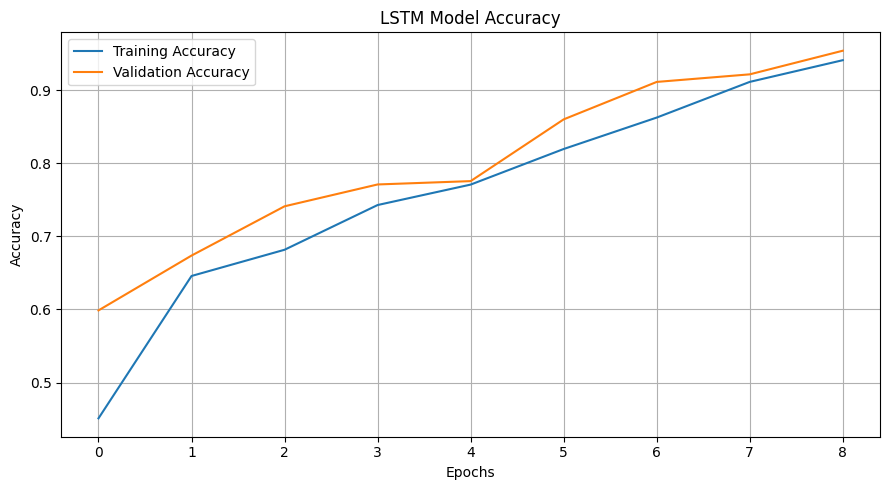

In [ ]:
plt.figure(figsize=(9, 5))

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("LSTM Model Accuracy")

plt.xlabel("Epochs")

plt.ylabel("Accuracy")

plt.legend()

plt.grid(True)

plt.tight_layout()

plt.savefig(
    "results/accuracy.png",
    dpi=300
)

plt.show()

In [ ]:
print("Saved Model Files:")

for file in os.listdir("models"):
    print(file)

print("\nSaved Result Files:")

for file in os.listdir("results"):
    print(file)

Saved Model Files:
label_encoder.pkl
best_language_lstm.keras
language_lstm.keras
tokenizer.json

Saved Result Files:
training_history.json
text_length_distribution.png
model_architecture.png
accuracy.png
training_history.csv


In [ ]:
from tensorflow.keras.models import load_model

model = load_model("models/best_language_lstm.keras")

print("Best LSTM model loaded successfully!")

Best LSTM model loaded successfully!


In [ ]:
test_loss, test_accuracy = model.evaluate(
    X_test_pad,
    y_test_encoded,
    verbose=1
)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy * 100, "%")

103/103 ━━━━━━━━━━━━━━━━━━━━ 20s 186ms/step - accuracy: 0.9604 - loss: 0.1580
Test Loss: 0.15796294808387756
Test Accuracy: 96.03537917137146 %


In [ ]:
y_pred_prob = model.predict(
    X_test_pad,
    batch_size=64
)

y_pred_encoded = np.argmax(
    y_pred_prob,
    axis=1
)

y_pred = label_encoder.inverse_transform(
    y_pred_encoded
)

y_actual = label_encoder.inverse_transform(
    y_test_encoded
)

print("Predictions generated successfully!")
print("\nFirst 10 Predictions:")
for i in range(10):
    print(
        "Actual:", y_actual[i],
        "| Predicted:", y_pred[i]
    )

52/52 ━━━━━━━━━━━━━━━━━━━━ 14s 263ms/step
Predictions generated successfully!

First 10 Predictions:
Actual: Romanian | Predicted: Romanian
Actual: Turkish | Predicted: Turkish
Actual: Romanian | Predicted: Romanian
Actual: Thai | Predicted: Thai
Actual: Korean | Predicted: Korean
Actual: Hindi | Predicted: Hindi
Actual: Russian | Predicted: Russian
Actual: Japanese | Predicted: Japanese
Actual: Indonesian | Predicted: Indonesian
Actual: Persian | Predicted: Persian


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

accuracy = accuracy_score(
    y_actual,
    y_pred
)

precision = precision_score(
    y_actual,
    y_pred,
    average="weighted",
    zero_division=0
)

recall = recall_score(
    y_actual,
    y_pred,
    average="weighted",
    zero_division=0
)

f1 = f1_score(
    y_actual,
    y_pred,
    average="weighted",
    zero_division=0
)

print("MODEL PERFORMANCE")

print("-------------------------")

print("Accuracy:", round(accuracy * 100, 2), "%")

print("Precision:", round(precision, 4))

print("Recall:", round(recall, 4))

print("F1 Score:", round(f1, 4))

MODEL PERFORMANCE
-------------------------
Accuracy: 96.04 %
Precision: 0.9639
Recall: 0.9604
F1 Score: 0.9608


In [ ]:
from sklearn.metrics import classification_report

report = classification_report(
    y_actual,
    y_pred,
    labels=label_encoder.classes_,
    zero_division=0
)

print(report)

report_dict = classification_report(
    y_actual,
    y_pred,
    labels=label_encoder.classes_,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report_dict).transpose()

report_df.to_csv(
    "results/classification_report.csv"
)

print("Classification report saved successfully!")

              precision    recall  f1-score   support

      Arabic       1.00      0.99      1.00       149
     Chinese       0.99      0.99      0.99       150
       Dutch       0.88      0.95      0.92       149
     English       0.75      0.96      0.84       150
    Estonian       0.99      0.94      0.96       150
      French       0.96      0.90      0.93       149
       Hindi       1.00      0.99      0.99       149
  Indonesian       0.99      0.97      0.98       146
    Japanese       0.99      0.99      0.99       150
      Korean       1.00      0.99      1.00       150
       Latin       0.96      0.77      0.85       143
     Persian       1.00      0.99      1.00       150
   Portugese       0.89      0.87      0.88       150
      Pushto       1.00      0.93      0.96       149
    Romanian       0.99      0.99      0.99       150
     Russian       1.00      0.98      0.99       150
     Spanish       0.87      0.95      0.91       149
     Swedish       0.97    

In [ ]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    y_actual,
    y_pred,
    labels=label_encoder.classes_
)

print("Confusion Matrix Shape:", cm.shape)

Confusion Matrix Shape: (22, 22)


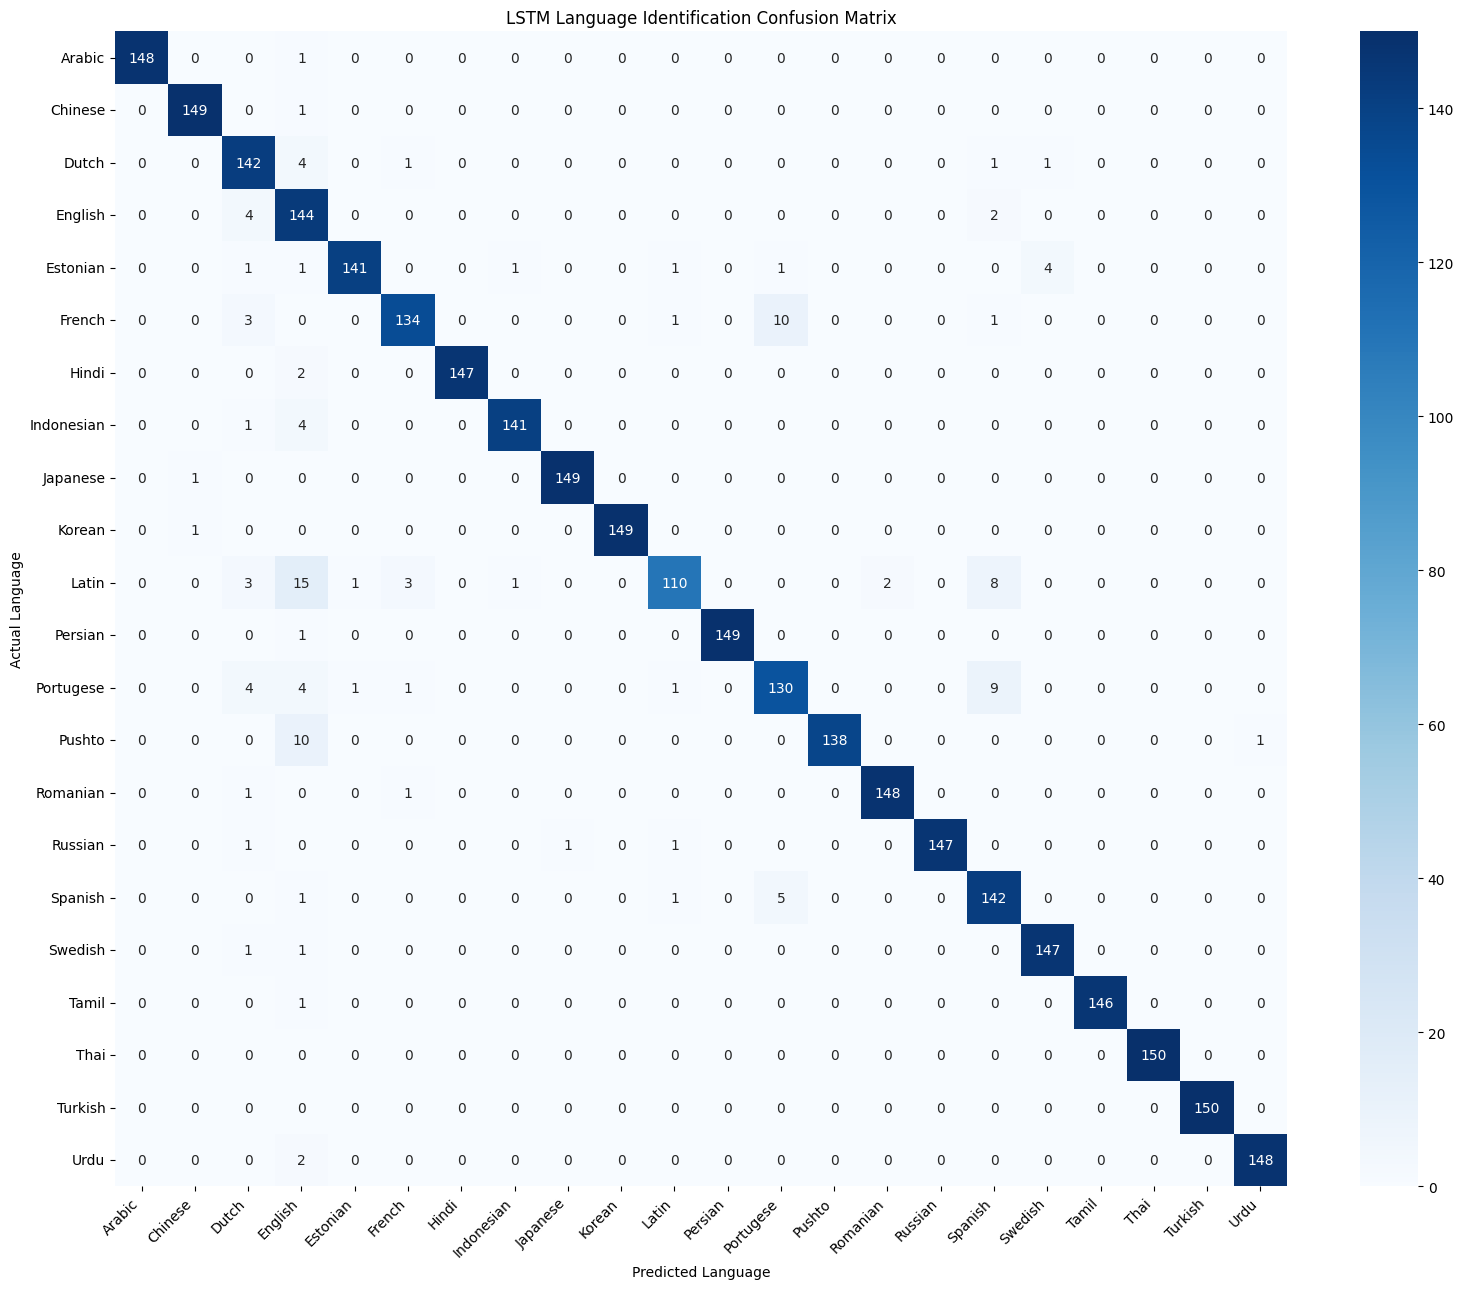

In [ ]:
plt.figure(figsize=(16, 13))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.title("LSTM Language Identification Confusion Matrix")

plt.xlabel("Predicted Language")

plt.ylabel("Actual Language")

plt.xticks(rotation=45, ha="right")

plt.yticks(rotation=0)

plt.tight_layout()

plt.savefig(
    "results/confusion_matrix.png",
    dpi=300
)

plt.show()

In [ ]:
misclassified = []

for i in range(len(y_actual)):

    if y_actual[i] != y_pred[i]:

        misclassified.append({
            "Text": X_test[i],
            "Actual Language": y_actual[i],
            "Predicted Language": y_pred[i],
            "Confidence": float(
                np.max(y_pred_prob[i])
            )
        })

misclassified_df = pd.DataFrame(misclassified)

print("Total Incorrect Predictions:", len(misclassified_df))

display(misclassified_df.head(10))

Total Incorrect Predictions: 130


,Text,Actual Language,Predicted Language,Confidence
0,snijders paul jacques dadelswärd-fersen und se...,Dutch,Swedish,0.988916
1,muqaghali maqatayev natus in februarii in qa...,Latin,Estonian,0.995847
2,per la chiesa e per gli uomini don giovanni ro...,Spanish,Latin,0.614953
3,"""scincomagus"" in w hazlitt the classical gazet...",Latin,English,0.601160
4,la chapelle-dabondance est une commune françai...,French,Portugese,0.778359
5,tamaulipas huasteeks tamaholipa is een staat i...,Dutch,Spanish,0.328573
6,"girard rené ""to double business bound"" essays...",Latin,English,0.606588
7,“we are deeply saddened and deeply touched by ...,Pushto,English,0.850674
8,armenia and the crusades tenth to twelfth cent...,Dutch,English,0.865430
9,farrington d p b interactions between individu...,Portugese,Dutch,0.334084


In [ ]:
misclassified_df.to_csv(
    "results/misclassified_samples.csv",
    index=False
)

print("Misclassified samples saved!")

Misclassified samples saved!


In [ ]:
metrics = {
    "Test Accuracy": accuracy,
    "Test Loss": float(test_loss),
    "Precision": precision,
    "Recall": recall,
    "F1 Score": f1,
    "Epochs Configured": EPOCHS,
    "Batch Size": BATCH_SIZE,
    "LSTM Units": LSTM_UNITS,
    "Embedding Dimension": EMBEDDING_DIM
}

metrics_df = pd.DataFrame(
    [metrics]
)

metrics_df.to_csv(
    "results/evaluation_metrics.csv",
    index=False
)

display(metrics_df)

print("Evaluation metrics saved successfully!")

,Test Accuracy,Test Loss,Precision,Recall,F1 Score,Epochs Configured,Batch Size,LSTM Units,Embedding Dimension
0,0.960354,0.157963,0.963905,0.960354,0.960794,9,64,128,128


Evaluation metrics saved successfully!


In [ ]:
cm_df = pd.DataFrame(
    cm,
    index=label_encoder.classes_,
    columns=label_encoder.classes_
)

cm_df.to_csv(
    "results/confusion_matrix.csv"
)

print("Confusion matrix data saved!")

Confusion matrix data saved!


In [ ]:
print("=" * 45)

print("TEXT LANGUAGE IDENTIFICATION USING LSTM")

print("=" * 45)

print("Number of Languages:", num_classes)

print("Training Samples:", len(X_train))

print("Validation Samples:", len(X_val))

print("Testing Samples:", len(X_test))

print("-" * 45)

print("Test Accuracy:", round(accuracy * 100, 2), "%")

print("Precision:", round(precision, 4))

print("Recall:", round(recall, 4))

print("F1 Score:", round(f1, 4))

print("Test Loss:", round(float(test_loss), 4))

print("Incorrect Predictions:", len(misclassified_df))

print("=" * 45)

TEXT LANGUAGE IDENTIFICATION USING LSTM
Number of Languages: 22
Training Samples: 15300
Validation Samples: 3279
Testing Samples: 3279
---------------------------------------------
Test Accuracy: 96.04 %
Precision: 0.9639
Recall: 0.9604
F1 Score: 0.9608
Test Loss: 0.158
Incorrect Predictions: 130
